# The electronic front end

This tutorial walks through how `src/molecules.py` turns a real molecule into the same type of matrix the selection engine uses. It takes about 25 minutes and picks up where Tutorial 2 left off.

Nothing here needs `make`. The guess cells work the same way as before: replace `None` with your answer, run that cell, then run the one after it to check.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
from pyscf import fci, gto, scf
from pyscf.fci import cistring
from scipy.linalg import eigh

ROOT = "../.."
sys.path.append(f"{ROOT}/src")
from molecules import MOLECULES, fci_hamiltonian, integrals
from utils import epstein_nesbet_order, ground_state, reference_config, subspace_energy

plt.style.use(f"{ROOT}/figures.mplstyle")
os.makedirs(f"{ROOT}/figures/week3", exist_ok=True)
MHA = 1000  # hartree to millihartree


def check(guess, answer, tol=0):
    if guess is None:
        print("Put your guess in first, then run this cell again")
        return
    right = guess == answer if isinstance(answer, str) else abs(guess - answer) <= tol
    print(f"Correct, it's {answer}" if right else f"Not quite. You said {guess}, it's {answer}")

## From a molecule to orbitals

PySCF starts with Hartree-Fock, where each electron moves in the average field of all the others. What comes out is a set of orbitals, the slots the electrons can sit in.

How many orbitals we get depends on the basis set, the functions PySCF builds the orbitals from. STO-3G is the smallest common one. It gives each atom one function for every orbital in the shells its electrons reach, core included, so lithium gets 1s, 2s and three 2p functions and hydrogen gets 1s.

How many orbitals does LiH have in STO-3G?

In [2]:
my_guess = None

Now we'll build the molecule and check.

In [3]:
mol = gto.M(**MOLECULES["lih"], verbose=0)
check(my_guess, mol.nao)
print(f"{mol.nao} orbitals, {mol.nelec[0]} alpha and {mol.nelec[1]} beta electrons")

Put your guess in first, then run this cell again
6 orbitals, 2 alpha and 2 beta electrons


## From orbitals to configurations

For a molecule, a configuration is called a determinant. It says which orbitals the alpha (up) electrons fill and which the beta (down) electrons fill. Just like the Hubbard chain in Tutorial 2, it is a pair of bit strings, one per spin.

LiH has 6 orbitals and 2 electrons of each spin. How many determinants is that? Count the ways to place the alpha electrons, then the ways to place the beta ones.

In [4]:
my_guess = None

We'll ask PySCF for the alpha strings and check.

In [5]:
alpha = cistring.make_strings(range(mol.nao), mol.nelec[0])
check(my_guess, len(alpha) * len(alpha))
print(f"{len(alpha)} alpha strings, the first few in binary:")
for a in alpha[:5]:
    print(f"  {a:06b}")

Put your guess in first, then run this cell again
15 alpha strings, the first few in binary:
  000011
  000101
  000110
  001001
  001010


Read each string from the right, so the last digit is orbital 0. The first string is `000011`, the two lowest orbitals filled, which is the Hartree-Fock filling.

PySCF orders determinants alpha first. Row 0 pairs the first alpha string with the first beta string, row 1 pairs it with the second beta string, and so on through every beta string before the alpha string changes.

## Building the matrix

`integrals` runs Hartree-Fock and returns the one- and two-electron integrals, and `fci_hamiltonian` turns them into the full matrix over every determinant. It does not build the matrix itself. PySCF already builds a block of it, a few hundred determinants, to speed up its own solver, and we ask for every determinant instead.

In [6]:
h1, h2, ecore, norb, nelec, e_hf = integrals("lih")
H = fci_hamiltonian(h1, h2, ecore, norb, nelec)
print(f"H has a shape of {H.shape}, {np.count_nonzero(np.abs(H) > 1e-12) / H.size:.1%} filled")
print(f"Symmetric: {np.allclose(H, H.T)}")

H has a shape of (225, 225), 12.4% filled
Symmetric: True


Before we trust it, we'll check it against PySCF's own full CI solver. For a matrix this small, PySCF would normally just diagonalize the same block we built, which would be checking our matrix against itself. So we force it down a separate route that only ever multiplies the matrix by vectors.

In [7]:
E_ours = eigh(H, eigvals_only=True)[0]
solver = fci.FCI(scf.RHF(mol).run())
solver.davidson_only = True  # skip the shortcut that reuses our block
E_pyscf = solver.kernel()[0]
print(f"Ours  {E_ours:.10f} hartree")
print(f"PySCF {E_pyscf:.10f} hartree")
print(f"Difference {abs(E_ours - E_pyscf):.1e}")

Ours  -7.8823243789 hartree
PySCF -7.8823243789 hartree
Difference 2.0e-14


Notice that the two match to every digit printed, so the matrix is right.

## Row 0 is Hartree-Fock

Each diagonal entry is the energy of one determinant on its own. The Hartree-Fock determinant is the best single determinant there is, so its diagonal entry should be the Hartree-Fock energy.

Before you look: is the exact energy above or below the Hartree-Fock energy? Answer "above" or "below".

In [8]:
my_guess = None

In [9]:
print(f"Hartree-Fock energy   {e_hf:.6f}")
print(f"Diagonal entry, row 0 {H[0, 0]:.6f}")
print(f"Exact energy          {E_ours:.6f}")
print(f"Cheapest row on the diagonal: {reference_config(H)}")
check(my_guess, "below" if E_ours < e_hf else "above")

Hartree-Fock energy   -7.861865
Diagonal entry, row 0 -7.861865
Exact energy          -7.882324
Cheapest row on the diagonal: 0
Put your guess in first, then run this cell again


The gap between Hartree-Fock and the exact answer is called the correlation energy, about 20 millihartree (mHa) for LiH. Chemical accuracy is usually taken as 1.6 mHa, so Hartree-Fock on its own is off by more than ten times that.

Notice also that the cheapest row on the diagonal is row 0. That is the configuration `reference_config` hands perturbation theory as its starting point, the same function we used on the model systems.

## When one configuration is not enough

Our second molecule is four hydrogen atoms in a line, 1.5 angstrom apart. A normal H-H bond is about 0.74 angstrom, so these bonds are stretched about twice as far. We use the larger 6-31G basis here, which gives 8 orbitals.

LiH puts about 97% of its exact ground state on Hartree-Fock. What fraction do you think stretched H4 puts there? Give a decimal, within 0.05.

In [10]:
my_guess = None

In [11]:
systems = {}
for m in ["lih", "h4"]:
    h1, h2, ecore, norb, nelec, e_hf = integrals(m)
    H_m = fci_hamiltonian(h1, h2, ecore, norb, nelec)
    E0, c0 = ground_state(H_m)
    systems[m] = (H_m, E0, c0)
    print(f"{m}: {len(H_m)} determinants, Hartree-Fock weight {c0[0] ** 2:.3f}")

check(my_guess, round(float(systems["h4"][2][0] ** 2), 2), tol=0.05)

lih: 225 determinants, Hartree-Fock weight 0.974


h4: 784 determinants, Hartree-Fock weight 0.804
Put your guess in first, then run this cell again


Stretching the bonds spreads the answer over more determinants. In a stretched bond the electrons no longer pair up neatly in one orbital, so Hartree-Fock's one-determinant picture gets worse. We'll plot the sorted weights for both molecules.

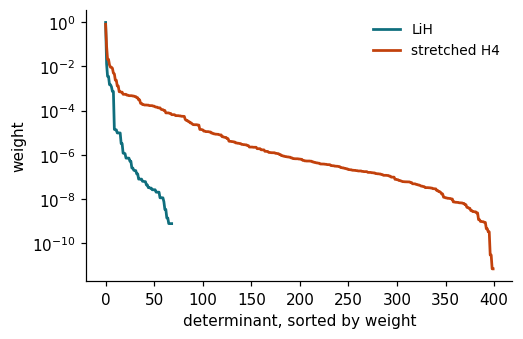

In [12]:
fig, ax = plt.subplots(figsize=(5, 3.2))
for m, c, name in [("lih", "#0f6e7d", "LiH"), ("h4", "#c2410c", "stretched H4")]:
    w = np.sort(systems[m][2] ** 2)[::-1]
    ax.semilogy(w[w > 1e-14], c=c, label=name)
ax.set_xlabel("determinant, sorted by weight")
ax.set_ylabel("weight")
ax.legend()
fig.savefig(f"{ROOT}/figures/week3/weights.svg")
plt.show()

Notice how much more slowly the H4 curve falls. That spread is what makes stretched H4 the harder test for choosing configurations. Each line stops where the remaining weights are exactly zero, which the molecule's symmetry forces.

## How many determinants each one needs

We'll run perturbation theory from the selection engine on both molecules and count how many determinants it takes to get within chemical accuracy.

LiH: 6 determinants to get under 1.6 mHa


stretched H4: 84 determinants to get under 1.6 mHa


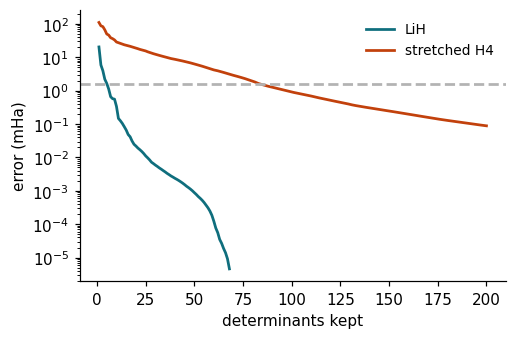

In [13]:
fig, ax = plt.subplots(figsize=(5, 3.2))
for m, c, name in [("lih", "#0f6e7d", "LiH"), ("h4", "#c2410c", "stretched H4")]:
    H_m, E0, _ = systems[m]
    order = epstein_nesbet_order(H_m, [reference_config(H_m)], 200)
    sizes = np.arange(1, 201)
    err = np.array([subspace_energy(H_m, order[:k]) - E0 for k in sizes]) * MHA
    shown = err > 1e-6  # stop the line once the error is effectively zero
    ax.semilogy(sizes[shown], err[shown], c=c, label=name)
    print(f"{name}: {sizes[np.argmax(err < 1.6)]} determinants to get under 1.6 mHa")
ax.axhline(1.6, c=(.7, .7, .7), ls="--")  # chemical accuracy, about 1 kcal/mol
ax.set_xlabel("determinants kept")
ax.set_ylabel("error (mHa)")
ax.legend()
fig.savefig(f"{ROOT}/figures/week3/truncation.svg")
plt.show()

LiH needs a handful of determinants and stretched H4 needs dozens. Both are a small fraction of the full matrix (225 and 784 determinants), which is the reason selection works at all.

## Stretching the bonds further

The cell below rebuilds H4 at any spacing and prints its Hartree-Fock weight. At 1.5 angstrom we know the answer is 0.80. Before you run it at 2.0 angstrom: does Hartree-Fock still hold more than half the weight? Answer "yes" or "no".

In [14]:
my_guess = None

In [15]:
spacing = 2.0  # angstrom
basis = "6-31g"

atoms = "; ".join(f"H 0 0 {i * spacing}" for i in range(4))
mol_s = gto.M(atom=atoms, basis=basis, verbose=0)
c0_s = fci.FCI(scf.RHF(mol_s).run()).kernel()[1]
weight = c0_s[0, 0] ** 2  # row 0, column 0 is Hartree-Fock

print(f"{basis}, {spacing} angstrom: {c0_s.size} determinants, Hartree-Fock weight {weight:.3f}")
check(my_guess, "yes" if weight > 0.5 else "no")

6-31g, 2.0 angstrom: 784 determinants, Hartree-Fock weight 0.570
Put your guess in first, then run this cell again


## Where this leaves us

Real molecules now come out in the same form as the model systems from Tutorial 2, a matrix with a label for each row, and the matrix matches PySCF's full CI. The parts of `molecules.py` still marked TODO finish the front end, and `pytest -q src/test_molecules.py` tells you when they are done. The next tutorial swaps the exact-weight sampler for a real quantum circuit.

## Things to try

Each of these is a one-line change to the last cell.

Set `spacing` to 2.5. Does Hartree-Fock still hold more than half the weight?

Set `spacing` to 0.75, close to a normal H-H bond. How close to 1 does the weight get?

Set `basis` to `"sto-3g"`, which leaves only 36 determinants. Does the Hartree-Fock weight go up or down?